In [1]:
from src.load_params import load_params, format_duration
import pandas as pd
from astropy.io import fits 
import os
from astropy.wcs import WCS
import matplotlib.patches as mpatches
from matplotlib.pyplot import cm
from astropy.visualization.wcsaxes import WCSAxes
import matplotlib.patches as patches
import matplotlib
import pickle
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from skimage import measure
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.visualization.wcsaxes import Quadrangle

matplotlib.rcParams.update({'font.size': 11})
matplotlib.rcParams.update({'axes.grid':False})
matplotlib.rcParams.update({'xtick.direction':'out'})
matplotlib.rcParams.update({'ytick.direction':'out'})
matplotlib.rcParams.update({'xtick.top':True})
matplotlib.rcParams.update({'ytick.right':True})
matplotlib.rcParams.update({'legend.fontsize':'small'})
matplotlib.rcParams.update({'legend.frameon':False})
matplotlib.rcParams.update({'legend.fancybox':False})
matplotlib.rcParams.update({'legend.framealpha':0.6})
matplotlib.rcParams.update({'lines.dashed_pattern':[7,3]})
matplotlib.rcParams.update({'lines.dashed_pattern':[7,3]})


from src.scan_fcts import *
from src.astrometry_fcts import *
from src.hdf5_fcts import *
offset2 = 0.0145 #sky angle separation of detectors in the LW array
offset1 = 0.0182 #sky angle separation of detectors in the SW array
EL1, XEL1 = pixelOffset(51, offset1, 0)
separation=0.066
EL2, XEL2 = pixelOffset(64, offset2, 0)


In [2]:
#Save your depthmap in a pickle and load it here: 
# The array of your hitmap goes here ! 
file = 'dict_dir/depthmaps_for_strategy_plot.p'
dict =  pickle.load( open(file, 'rb'))
h = 10 #hours
depthmap = dict[f'{h}h hitmap']

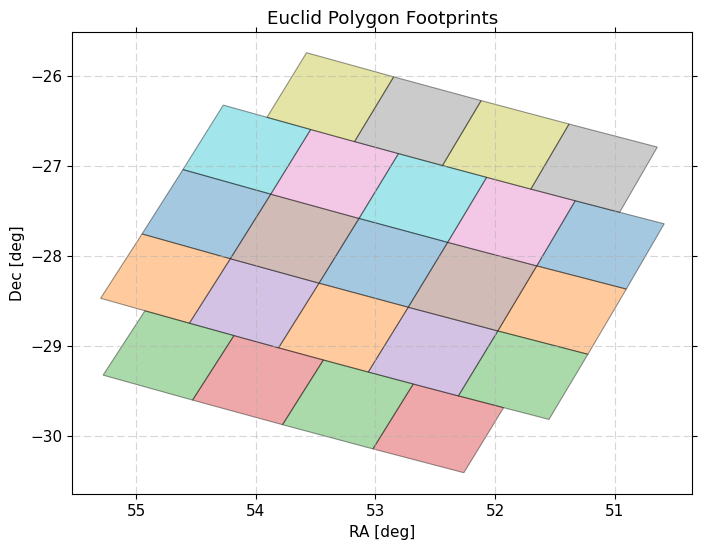

In [3]:
#Plot Euclid Mosaic if needed
polygons = [
    [(50.585853, -27.644678), (50.902896, -28.370438), (51.651550, -28.112633), (51.330259, -27.388680)],
    [(50.902775, -28.370157), (51.223920, -29.095156), (51.977045, -28.835778), (51.651435, -28.112564)],
    [(51.223872, -29.094851), (51.549421, -29.819124), (52.307059, -29.558040), (51.977039, -28.835567)],
    [(51.928784, -29.688937), (52.261115, -30.411604), (53.021536, -30.146543), (52.684516, -29.425819)],
    [(51.977005, -28.835685), (52.307026, -29.558158), (53.060758, -29.292837), (52.726389, -28.572241)],
    [(51.651435, -28.112564), (51.977045, -28.835778), (52.726315, -28.572265), (52.396513, -27.850868)],
    [(51.330144, -27.388611), (51.651550, -28.112633), (52.396513, -27.850868), (52.071013, -27.128622)],
    [(50.643457, -26.791823), (50.958647, -27.517318), (51.701255, -27.259222), (51.382031, -26.535410)],
    [(51.381611, -26.535441), (51.701065, -27.259178), (52.440171, -26.997106), (52.116833, -26.275027)],
    [(52.070938, -27.128647), (52.396513, -27.850868), (53.137897, -27.585053), (52.808298, -26.864604)],
    [(52.396513, -27.850868), (52.726315, -28.572265), (53.471935, -28.304710), (53.137897, -27.585053)],
    [(52.726315, -28.572265), (53.060724, -29.292954), (53.810546, -29.023558), (53.471935, -28.304710)],
    [(52.684335, -29.425985), (53.021211, -30.146756), (53.777552, -29.877536), (53.436251, -29.158735)],
    [(53.436030, -29.158806), (53.777186, -29.877654), (54.529491, -29.604313), (54.183935, -28.887325)],
    [(53.471860, -28.304734), (53.810472, -29.023581), (54.556487, -28.750127), (54.213657, -28.033135)],
    [(53.137897, -27.585053), (53.471935, -28.304710), (54.213769, -28.033206), (53.875667, -27.315354)],
    [(52.808222, -26.864628), (53.137935, -27.585148), (53.875704, -27.315448), (53.542138, -26.596771)],
    [(52.116452, -26.275149), (52.439944, -26.997179), (53.175612, -26.731160), (52.848223, -26.010814)],
    [(52.847955, -26.011004), (53.175459, -26.731420), (53.907637, -26.461622), (53.576402, -25.742964)],
    [(53.542024, -26.596913), (53.875666, -27.315566), (54.609895, -27.042002), (54.272409, -26.325098)],
    [(53.875667, -27.315354), (54.213769, -28.033206), (54.951906, -27.757769), (54.609861, -27.041696)],
    [(54.213657, -28.033135), (54.556301, -28.750079), (55.298427, -28.472743), (54.951646, -27.757531)],
    [(54.183674, -28.887301), (54.529085, -29.604334), (55.277398, -29.326907), (54.927677, -28.611815)]
]

# Plot
plt.figure(figsize=(8, 6))

for poly in polygons:
    xs, ys = zip(*poly)
    # close the polygon by connecting last to first
    plt.fill(xs + (xs[0],), ys + (ys[0],), alpha=0.4, edgecolor='black', linewidth=0.8)

plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")
plt.title("Euclid Polygon Footprints")
plt.gca().invert_xaxis()  # optional, common in astronomy
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Set MJD-END to 55759.437826 from DATE-END'. [astropy.wcs.wcs]


"\n#Overplot Euclid mosaic\nfor poly in polygons:\n    xs, ys = zip(*poly)\n    # close the polygon by connecting last to first\n    plt.plot(xs + (xs[0],), ys + (ys[0],), '-', color='black', linewidth=1,transform=ax1.get_transform('world'))\n"

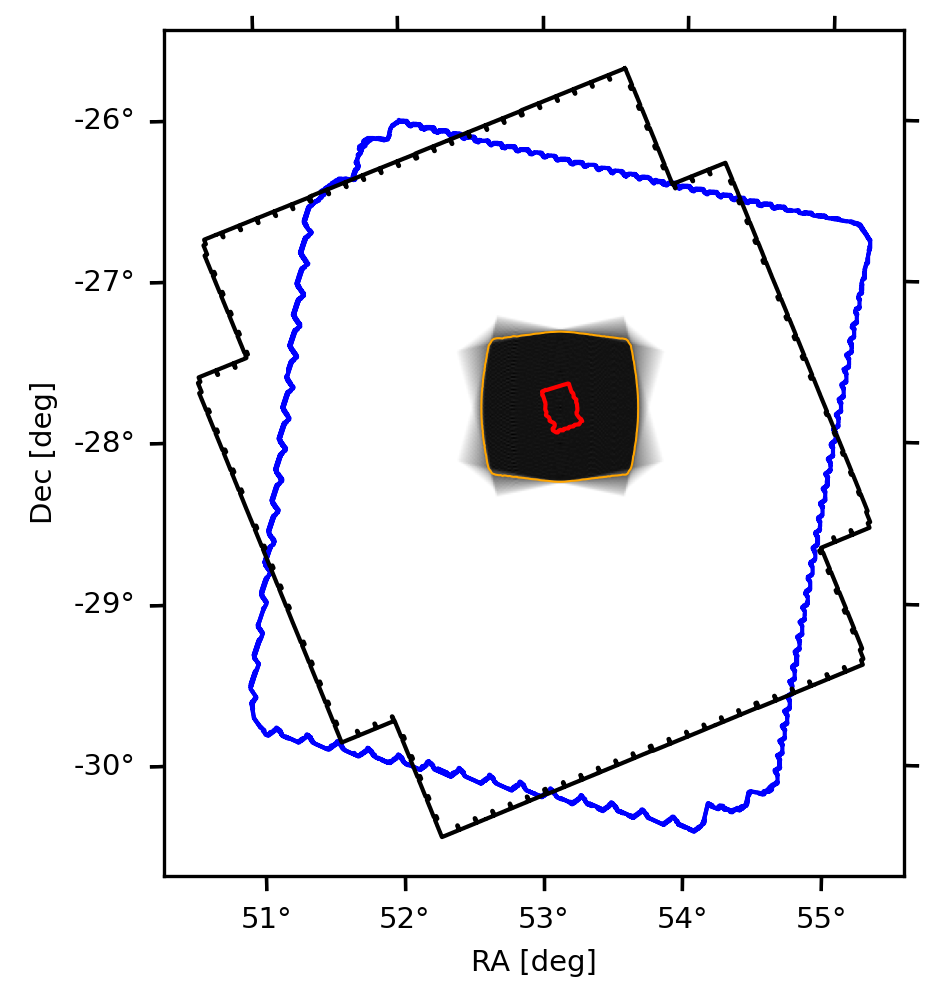

In [5]:
matplotlib.rcParams.update({'font.size': 7})
matplotlib.rcParams.update({'axes.grid':False})
matplotlib.rcParams.update({'xtick.direction':'out'})
matplotlib.rcParams.update({'ytick.direction':'out'})
matplotlib.rcParams.update({'xtick.top':True})
matplotlib.rcParams.update({'ytick.right':True})
matplotlib.rcParams.update({'legend.fontsize':'small'})
matplotlib.rcParams.update({'legend.frameon':False})
matplotlib.rcParams.update({'legend.fancybox':False})
matplotlib.rcParams.update({'legend.framealpha':0.6})
matplotlib.rcParams.update({'lines.dashed_pattern':[7,3]})
matplotlib.rcParams.update({'lines.dashed_pattern':[7,3]})

#Load the coordinates of the field using Astropy.
name='Goods-S Field'
c=SkyCoord.from_name(name)
rafield = 53.11667
ra = rafield
dec = c.dec.value
lat = -77.83 #deg
res = 40/3600
hdr  = fits.getheader('datasets/pySIDES_from_uchuu_TIM_gaussian_tile0_1.414deg_1.414deg_res20arcsec_R250_full_de_Looze_smoothed_MJy_sr.fits')
hdr['CRVAL1'] = ra
hdr['CRVAL2'] = dec
hdr['CRPIX1'] = 76
hdr['CRPIX2'] = 76
hdr['CDELT1'] = res
hdr['CDELT2'] = res
wcs = WCS(hdr, naxis=2) 
depthcut=0.65

fig = plt.figure(figsize=(7, 7), dpi=300)
# Left panel with WCS
ax1 = fig.add_subplot(1, 2, 1, projection=wcs)
# --- WCS axis formatting ---
ax1.set_xlabel('RA [deg]')
ax1.set_ylabel('Dec [deg]')
ax1.coords[0].set_format_unit('deg', decimal=True)  # RA
ax1.coords[1].set_format_unit('deg', decimal=True)  # De

#Plot CANDELS
df = pd.read_csv('dict_dir/CANDELS_footprint.tsv', sep='\t', header=None, names=['RA', 'Dec'])
# Extract RA and Dec
raf = df['RA'].values
decf = df['Dec'].values
ax1.plot(raf, decf,  linestyle='-', color='red', transform=ax1.get_transform('world'), lw=1)

# --- WCS image ---
#Plot the hitmap

ax1.imshow(depthmap, origin='lower', cmap='binary')
area = len(depthmap[depthmap>=depthcut]) * res**2
for level, color in zip((0.65, 0.5),('orange',)):
    contours = ax1.contour(depthmap, levels=[level], colors=color, linewidths=0.5, )
    #Add label to the contours
    #ax1.clabel(contours,  colors='white')  # fmt can be a format string or function fmt=f"{area:.2f}"+"$\\rm deg^2$\nafter 11hrs",


#Overplot SPIRE and Euclid
for file, color, label in zip(('datasets/NE-CDFS-SWIRE_nested-image_SMAP250_DR2.fits','datasets/GOODS-S_EuclidV.fits',"fits_and_hdf5/GOODS-S_SPIRE-250.fits" ), ('b','k',), ('Euclid', 'SPIRE 250$\\rm \\mu m$')): 

    if('Euclid' in file or 'GOODS' in file): 
        # Load data and WCS
        data = fits.getdata(file)
        header = fits.getheader(file)
        wcs_field = WCS(header)

        # Mask: True where data is NOT NaN
        mask = ~np.isnan(data)

        # Extract contours at the 0.5 level
        contours = measure.find_contours(mask.astype(float), 0.5)
        contour = max(contours, key=lambda x: x.shape[0])  # largest contour
        contour_closed = np.vstack([contour, contour[0]])

        # Convert pixels -> RA/Dec
        ra_hershel, dec_hershel = wcs_field.all_pix2world(contour_closed[:, 1], contour_closed[:, 0], 0)

        # Convert to ICRS SkyCoord
        icrs_coords = SkyCoord(ra=ra_hershel, dec=dec_hershel, unit='deg', frame='icrs')
    else: 
        # Load data and WCS for NE-CDFS SMAP field
        hdu_smap = fits.open('datasets/NE-CDFS-SWIRE_nested-image_SMAP250_DR2.fits')[1]
        data = hdu_smap.data
        header = hdu_smap.header
        wcs_field = WCS(header)

        # Mask: True where data is NOT NaN
        mask = ~np.isnan(data)

        # Extract largest contour
        contours = measure.find_contours(mask.astype(float), 0.5)
        contour = max(contours, key=lambda x: x.shape[0])  # largest contour
        contour_closed = np.vstack([contour, contour[0]])

        # Pixel → RA/Dec
        ra_hershel, dec_hershel = wcs_field.all_pix2world(contour_closed[:, 1],
                                                        contour_closed[:, 0], 0)

        icrs_coords = SkyCoord(ra=ra_hershel, dec=dec_hershel,
                            unit='deg', frame='icrs')


    plt.plot(icrs_coords.ra.deg, icrs_coords.dec.deg, '-', color=color, lw=1,transform=ax1.get_transform('world')) 

fig.savefig('plots/TIM_strategy_with_candels_euclid_spire250.png', bbox_inches='tight', transparent=True)

'''
#Overplot Euclid mosaic
for poly in polygons:
    xs, ys = zip(*poly)
    # close the polygon by connecting last to first
    plt.plot(xs + (xs[0],), ys + (ys[0],), '-', color='black', linewidth=1,transform=ax1.get_transform('world'))
'''


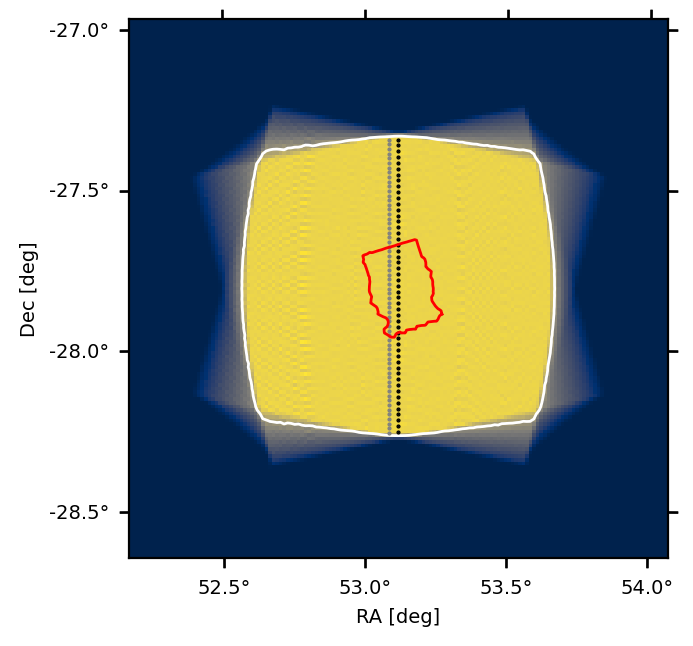

In [6]:
fig, ax1 = plt.subplots(figsize=(3.5, 3.5), dpi=200, subplot_kw={'projection': wcs},)
# Left panel with WCS
# --- WCS axis formatting ---
ax1.set_xlabel('RA [deg]')
ax1.set_ylabel('Dec [deg]')
ax1.coords[0].set_format_unit('deg', decimal=True)  # RA
ax1.coords[1].set_format_unit('deg', decimal=True)  # De
ax1.imshow(depthmap, origin='lower', cmap='cividis')
for level, color in zip((0.65, 0.5),('white',)):
    contours = ax1.contour(depthmap, levels=[level], colors=color, linewidths=1, )
    #Add label to the contours
    #ax1.clabel(contours,  colors=color, fmt=f"{area:.2f}"+"$\\rm deg^2$\nafter"+f" {h}hrs", fontsize=9) 


#Overplot the TIM instantaneous field of view
ax1.plot(XEL1+ra, dec + EL1 + offset1, 'ok', markersize=0.5, transform=ax1.get_transform('world'))
ax1.plot(XEL2 - separation/2+ra, dec + EL2 + offset2, 'o', c='gray', markersize=0.5, transform=ax1.get_transform('world'))

#Plot CANDELS
df = pd.read_csv('dict_dir/CANDELS_footprint.tsv', sep='\t', header=None, names=['RA', 'Dec'])
# Extract RA and Dec
raf = df['RA'].values
decf = df['Dec'].values
ax1.plot(raf, decf,  linestyle='-', color='red', transform=ax1.get_transform('world'), lw=1)

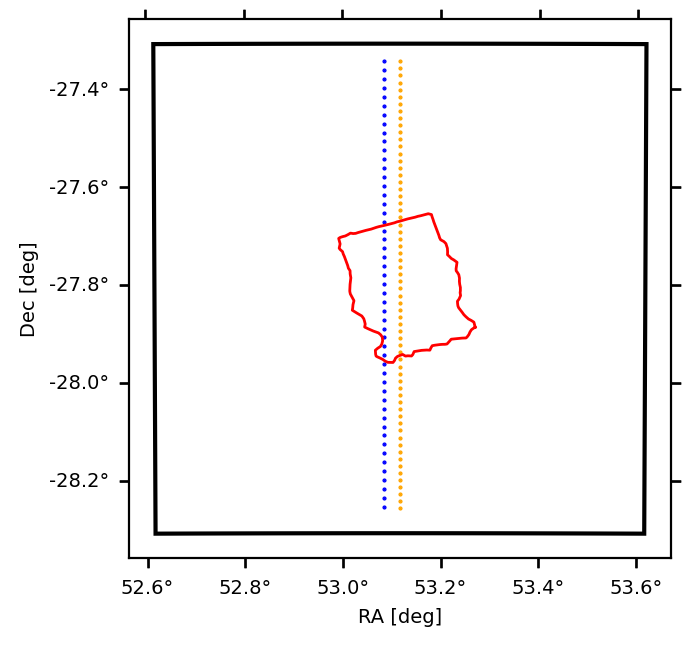

In [9]:
fig, ax1 = plt.subplots(figsize=(3.5, 3.5), dpi=200, subplot_kw={'projection': wcs},)
# Left panel with WCS
# --- WCS axis formatting ---
ax1.set_xlabel('RA [deg]')
ax1.set_ylabel('Dec [deg]')
ax1.coords[0].set_format_unit('deg', decimal=True)  # RA
ax1.coords[1].set_format_unit('deg', decimal=True)  # De
#ax1.imshow(depthmap, origin='lower', cmap='cividis')

center = SkyCoord(ra*u.deg, dec*u.deg, frame='icrs')

square = Quadrangle(
    (center.ra - 0.5*u.deg, center.dec - 0.5*u.deg),  # bottom-left corner
    1.0*u.deg,  # width
    1.0*u.deg,  # height
    edgecolor='k',
    facecolor='none',
    lw=1.5,
    transform=ax1.get_transform('world')
)

ax1.add_patch(square)

#Overplot the TIM instantaneous field of view
ax1.plot(XEL1+ra- separation/2, dec + EL1 + offset1, 'ob', markersize=0.5, transform=ax1.get_transform('world'))
ax1.plot(XEL2 +ra, dec + EL2 + offset2, 'o', c='orange', markersize=0.5, transform=ax1.get_transform('world'))

#Plot CANDELS
df = pd.read_csv('datasets/CANDELS_footprint.tsv', sep='\t', header=None, names=['RA', 'Dec'])
# Extract RA and Dec
raf = df['RA'].values
decf = df['Dec'].values
ax1.plot(raf, decf,  linestyle='-', color='red', transform=ax1.get_transform('world'), lw=1)